In [1]:
import psycopg2

In [2]:
import os
print(os.getcwd())

c:\Users\morga\OneDrive - Duke University\Coding Projects\Adyn DIIG\DIIG-F26-Adyn\morgan


In [3]:
import os
from dotenv import load_dotenv

load_dotenv()

conn = psycopg2.connect(
    host=os.environ["DB_HOST"],
    port=os.environ["DB_PORT"],
    dbname=os.environ["DB_NAME"],
    user=os.environ["DB_USER"],
    password=os.environ["DB_PASSWORD"]
)

In [4]:
with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxOrders LIMIT 10;")
    rows = cur.fetchall()

    for row in rows:
        print(row)

('225cfbd0-abd2-4781-a25b-5005a28a2092', 'ADRX1XZO0S4K', '9902067c-8ea2-46e7-9cd9-bcf9f72c2b61', 'cus_Lt4NfaGGdTncq7', 'processed', '5ef5834b-4b45-404e-85f4-a8727b6376d5', 'AD-BC-DAYSEE00', 2, 'Sig', 'ADYN', True, True, 0, None, 'price_1LGBy1ApFTaOcYxWBuNW1zcY', 'ii_1LeiCSApFTaOcYxW4etgDPKC', 'in_1LeiCsApFTaOcYxWIoCKfJ6N', datetime.datetime(2022, 9, 5, 16, 31, 4, 295483), datetime.datetime(2022, 9, 5, 16, 31, 30, 940148), datetime.datetime(2022, 9, 5, 16, 27, 40, 548207), datetime.datetime(2024, 1, 8, 20, 59, 59, 552053), None, True, True, None, None, False, None, True, None)
('03ea3b7d-0599-41ac-9a58-89071a1c5545', 'ADRXFXP5NRVS', '3bdea8bd-498e-4406-b26f-8a43886f0802', 'cus_PEKeIjw7gvoU1v', None, '47fb76f4-81cd-49d1-91b3-3348d73d3aba', 'AD-BC-FALMIN20', 1, '3', 'note', True, True, 5, None, 'price_1LHSwpApFTaOcYxW2Zu3uxBn', 'ii_1PBlceApFTaOcYxWDwNv8VWc', 'in_1PBld0ApFTaOcYxWTPkJZcG2', datetime.datetime(2024, 5, 1, 19, 10, 10, 516283), datetime.datetime(2024, 5, 1, 22, 27, 54, 904750),

In [5]:
#check column names of RxOrders
with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxOrders LIMIT 0;")
    print([col[0] for col in cur.description])

['id', 'friendly_order_id', 'customer_id', 'stripe_customer_id', 'status', 'prescriber_id', 'sku', 'quantity', 'signetur', 'note_to_pharmacy', 'bc_prescribed', 'rx_submitted_to_adyn_pharmacy', 'refills_allowed', 'customer_cost', 'stripe_price_id', 'stripe_invoice_item_id', 'stripe_invoice_id', 'date_order_placed', 'date_order_paid', 'created_date', 'modified_date', 'days_supply', 'customer_approved', 'adyn_approved', 'customer_disapproved_reason', 'adyn_disapproved_reason', 'suspended', 'suspended_reason', 'customer_visibility', 'appointment_id']


In [6]:
#check column names of RxOrderHistory
with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxOrderHistory LIMIT 0;")
    print([col[0] for col in cur.description])

['id', 'rxorder_id', 'new_values', 'created_date']


In [7]:
#check column names of RxPacked
with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxPacked LIMIT 0;")
    print([col[0] for col in cur.description])

['id', 'shipment_order', 'order_receipt_date_time', 'rx_number', 'fill_number', 'qty_req', 'qty_left', 'ship_to_state', 'ship_to_zip_code', 'packed_date_time', 'ship_date_time', 'bin_number', 'patient_amount_if_cash_or_house_charge', 'patient_copay_if_insured', 'primary_ins_name', 'primary_ins_bin', 'primary_ins_pcn', 'primary_ins_rx_group', 'primary_ins_plan_paid_amount', 'primary_ins_copay', 'primary_ins_disp_fee', 'sec_ins_name', 'sec_ins_bin', 'sec_ins_pcn', 'sec_ins_rx_group', 'sec_ins_plan_paid_amount', 'sec_ins_copay', 'sec_ins_disp_fee', 'drug_acquisition_cost', 'shipping_carrier_name', 'fill_date', 'tracking_number', 'created_date', 'modified_date', 'ship_to_address1', 'ship_to_address2', 'ship_to_city']


In [8]:
#check column names of RxWritten
with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxWritten LIMIT 0;")
    print([col[0] for col in cur.description])

['id', 'rx_number', 'rx_written_date_time', 'rx_creation_date_time', 'rx_expiration_date_time', 'script_status', 'ndc', 'patient_id', 'zip_code', 'total_fills', 'total_qty_authorized', 'rx_source', 'auto_refill', 'npi_provider_number', 'created_date', 'modified_date', 'customer_first_name', 'customer_last_name', 'customer_dob', 'customer_email']


In [9]:
#check column names of RxShipments
with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxShipments LIMIT 0;")
    print([col[0] for col in cur.description])

['id', 'customer_id', 'order_number', 'rx_order_id', 'email_id', 'tracking_number', 'date_shipped', 'shipped_via', 'first_name', 'last_name', 'address1', 'address2', 'city', 'state', 'zip', 'status', 'created_date', 'modified_date', 'status_checked', 'details', 'delivered_to_customer_date']


In [10]:
#check column names of RxMatches
with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxMatches LIMIT 0;")
    print([col[0] for col in cur.description])

['id', 'rx_order_id', 'rx_packed_id', 'rx_shipments_id', 'status', 'matcher_id', 'resolution', 'reason_for_no_charge', 'created_date', 'modified_date']


In [11]:
#check row count
with conn.cursor() as cur:
    
    cur.execute("SELECT COUNT(*) FROM RxOrders;")
    print("RxOrders:", cur.fetchone()[0])
    
with conn.cursor() as cur:
    
    cur.execute("SELECT COUNT(*) FROM RxOrderHistory;")
    print("RxOrderHistory:", cur.fetchone()[0])
    

with conn.cursor() as cur:
    
    cur.execute("SELECT COUNT(*) FROM RxPacked;")
    print("RxPacked:", cur.fetchone()[0])

with conn.cursor() as cur:
    
    cur.execute("SELECT COUNT(*) FROM RxWritten;")
    print("RxWritten:", cur.fetchone()[0])
    
with conn.cursor() as cur:
    
    cur.execute("SELECT COUNT(*) FROM RxShipments;")
    print("RxShipments:", cur.fetchone()[0])
    
with conn.cursor() as cur:
    
    cur.execute("SELECT COUNT(*) FROM RxMatches;")
    print("RxMatches:", cur.fetchone()[0])

RxOrders: 228
RxOrderHistory: 655
RxPacked: 745
RxWritten: 304
RxShipments: 81
RxMatches: 29


In [12]:
conn.rollback()

In [13]:
#convert to python df
import pandas as pd

with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxOrders;")
    rows = cur.fetchall()
    columns = [col[0] for col in cur.description]

rx_orders = pd.DataFrame(rows, columns=columns)

print(rx_orders.head())
print(rx_orders.shape)  # (rows, columns)

                                     id friendly_order_id  \
0  225cfbd0-abd2-4781-a25b-5005a28a2092      ADRX1XZO0S4K   
1  03ea3b7d-0599-41ac-9a58-89071a1c5545      ADRXFXP5NRVS   
2  30543457-bfb4-409e-a5a0-9349ee194a2f      ADRXY9ZUJCVQ   
3  81946797-e7e3-40a4-84df-609a15558574      ADRX016WT9IW   
4  92161f29-2c06-4480-8461-5c06ccbb528a      ADRXO1S03NV9   

                            customer_id  stripe_customer_id     status  \
0  9902067c-8ea2-46e7-9cd9-bcf9f72c2b61  cus_Lt4NfaGGdTncq7  processed   
1  3bdea8bd-498e-4406-b26f-8a43886f0802  cus_PEKeIjw7gvoU1v        NaN   
2  44df375b-d300-4198-9ae9-975fb964055b  cus_L2oXCt50e8J0Li        NaN   
3  5bbc7685-bb7b-465e-bf49-7ac57ce72f52  cus_NDGwGJq1PGPVHF        NaN   
4  7b7eb277-38eb-4daf-9df0-e6d839ff63f6  cus_NrLE4YBNo9gKSR   Archived   

                          prescriber_id             sku  quantity signetur  \
0  5ef5834b-4b45-404e-85f4-a8727b6376d5  AD-BC-DAYSEE00         2      Sig   
1  47fb76f4-81cd-49d1-91b3-3348d

In [14]:
#convert to python df
import pandas as pd

with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxOrderHistory;")
    rows = cur.fetchall()
    columns = [col[0] for col in cur.description]

rx_order_history = pd.DataFrame(rows, columns=columns)

print(rx_order_history.head())
print(rx_order_history.shape)  # (rows, columns)

                                     id                            rxorder_id  \
0  9fd0f0a2-443a-4e16-abfd-c1c7bf2881f4  9201ffe9-342c-4060-a25e-d65d3810d29e   
1  c2fab48a-a7ff-4675-9e74-3155680c836e  92161f29-2c06-4480-8461-5c06ccbb528a   
2  35036c25-cab4-4ba0-bb1d-688079339df2  92161f29-2c06-4480-8461-5c06ccbb528a   
3  f955963e-d149-4e39-8e33-3b25074be4a6  92161f29-2c06-4480-8461-5c06ccbb528a   
4  3319eca9-ecdd-4027-b866-66301ef47640  92161f29-2c06-4480-8461-5c06ccbb528a   

                                          new_values  \
0  {'id': '9201ffe9-342c-4060-a25e-d65d3810d29e',...   
1  {'id': '92161f29-2c06-4480-8461-5c06ccbb528a',...   
2  {'id': '92161f29-2c06-4480-8461-5c06ccbb528a',...   
3  {'id': '92161f29-2c06-4480-8461-5c06ccbb528a',...   
4  {'id': '92161f29-2c06-4480-8461-5c06ccbb528a',...   

                created_date  
0 2023-10-27 01:26:08.784704  
1 2023-12-11 23:33:05.345411  
2 2023-12-11 23:35:12.731150  
3 2023-12-11 23:35:40.153091  
4 2023-12-11 23:37:29

In [15]:
#convert to python df
import pandas as pd

with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxPacked;")
    rows = cur.fetchall()
    columns = [col[0] for col in cur.description]

rx_packed = pd.DataFrame(rows, columns=columns)

print(rx_packed.head())
print(rx_packed.shape)  # (rows, columns)

                                     id shipment_order  \
0  722edc8d-d5d2-4dbb-8706-f20dca0097a3        EJFY1PG   
1  4673e3e6-0aa3-4fc0-b23f-9fbf24ff67bf        DDMRDZN   
2  abd5e5eb-9e95-4837-b1db-7e4ad18eeeb5        UDSFDAO   
3  be213e1d-7ef6-49e8-a5dc-1188c84b44fd        QV57OCG   
4  18f33932-753b-4d53-af2a-4775d4485774        N7NOBHM   

     order_receipt_date_time rx_number fill_number  qty_req  qty_left  \
0 2023-05-11 14:39:10.599092   XXC72O5     X1ME25P      0.0      84.0   
1 2023-05-11 14:41:16.915695   83QS4Y6     2XCCURQ      0.0      84.0   
2 2023-05-11 14:42:02.418655   XHN4ZFZ     3JGZ0AJ      0.0      84.0   
3 2023-05-26 18:35:59.986101   FBLCKZH     TPE18Q8      0.0      84.0   
4 2023-05-26 19:24:26.959865   SHOOV4A     64Y3H94      0.0      84.0   

  ship_to_state ship_to_zip_code           packed_date_time  ...  \
0            WA            98122 2023-05-11 14:39:10.599092  ...   
1            WA            98122 2023-05-11 14:41:16.915695  ...   
2       

In [16]:
#convert to python df
import pandas as pd

with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxWritten;")
    rows = cur.fetchall()
    columns = [col[0] for col in cur.description]

rx_written = pd.DataFrame(rows, columns=columns)

print(rx_written.head())
print(rx_written.shape)  # (rows, columns)

                                     id rx_number       rx_written_date_time  \
0  a9085188-a3b2-4041-8f3c-30f648a65212   XXC72O5 2023-05-11 14:39:10.599092   
1  35824596-5f57-4fdf-b0f2-c93d1408d85d   83QS4Y6 2023-05-11 14:41:16.915695   
2  179c0e3f-2810-4d82-826b-33850c8c5396   XHN4ZFZ 2023-05-11 14:42:02.418655   
3  a2f2a330-8cd5-45ea-b616-47f18154f9a8   FBLCKZH 2023-05-26 18:35:59.986101   
4  c19df9ab-8953-4dae-920a-a5e7fcc13e54   SHOOV4A 2023-05-26 19:24:26.959865   

       rx_creation_date_time rx_expiration_date_time script_status  \
0 2023-05-11 14:39:10.599092     2023-05-24 22:51:58             A   
1 2023-05-11 14:41:16.915695     2023-05-24 22:51:58             A   
2 2023-05-11 14:42:02.418655     2023-05-24 22:51:58             A   
3 2023-05-26 18:35:59.986101     2023-05-27 18:43:15             A   
4 2023-05-26 19:24:26.959865     2023-05-27 19:43:15             A   

            ndc patient_id zip_code  total_fills  total_qty_authorized  \
0  68180-865-71   RWLZIN

In [17]:
#convert to python df
import pandas as pd

with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxShipments;")
    rows = cur.fetchall()
    columns = [col[0] for col in cur.description]

rx_shipments = pd.DataFrame(rows, columns=columns)

print(rx_shipments.head())
print(rx_shipments.shape)  # (rows, columns)

                                     id                           customer_id  \
0  7692c921-c706-4663-9da6-68e803671444  9fa25687-1b09-44d9-916c-3322b6f9b9cd   
1  8933cfb7-fa83-4333-a074-3694ed69de54  c17da20f-8034-418e-9183-5dad7b0ae3d0   
2  9f8e96cf-0741-4614-a127-bf09d9203916  9fa25687-1b09-44d9-916c-3322b6f9b9cd   
3  6a2c759e-1c44-4b71-abf7-98e2b1fa256b  9fa25687-1b09-44d9-916c-3322b6f9b9cd   
4  39e84e4a-3bf4-4250-827f-a22585a1d682  9fa25687-1b09-44d9-916c-3322b6f9b9cd   

  order_number                           rx_order_id  \
0          NaN  f9d07f8b-bc06-4101-82e3-83b2bdbe404c   
1          NaN  358e15b1-003a-473b-94c8-0301ac9b9d35   
2          NaN  0be57543-7472-431e-bbfa-819000dc9ff4   
3      1373XXX  91687557-50b6-48f0-882e-54d115457a40   
4      1373XXX  b3308b92-fa8c-4f6d-8da7-46e2f8b56494   

                                   email_id          tracking_number  \
0                                       NaN   9400111206207366050000   
1                               

In [18]:
#convert to python df
import pandas as pd

with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxMatches;")
    rows = cur.fetchall()
    columns = [col[0] for col in cur.description]

rx_matches = pd.DataFrame(rows, columns=columns)

print(rx_matches.head())
print(rx_matches.shape)  # (rows, columns)

                                     id                           rx_order_id  \
0  fd6212fb-7573-40ec-a2f7-9aa380600a6c  001a5ef9-426b-4435-afef-184004485271   
1  d036bbb1-786e-4a2e-9aea-660e4f532265  071a33bb-d28a-4512-8db8-02a54f34b8de   
2  ad090928-9ce7-4781-9bbb-4133f13e9f61  78e9d9bf-9179-42de-98d9-561dbb35437e   
3  7945de0b-570d-4520-9f30-edf3679ea374  358e15b1-003a-473b-94c8-0301ac9b9d35   
4  f814cf82-d36c-49e0-925d-e5d47e75b8ef  358e15b1-003a-473b-94c8-0301ac9b9d35   

                           rx_packed_id                       rx_shipments_id  \
0  010e6096-9027-4da6-af4b-245c57a22f91  7692c921-c706-4663-9da6-68e803671444   
1  022e8a0c-e081-40e7-bbc8-5ef079d52ab1  18e2c047-8dff-4714-97db-6559a232cefa   
2  86cf5fb0-d350-4df6-8609-edd0eff65597  9aec5ee7-a787-4d30-81db-43a40434e90c   
3  35e01470-8a1f-48f1-9731-5d442292da8b  8b256a11-7b9f-46f3-b13e-16b7e2659df5   
4  70f76b6c-f21a-4620-910c-787d1643c3d0  8933cfb7-fa83-4333-a074-3694ed69de54   

         status           

In [19]:
rx_orders.columns

Index(['id', 'friendly_order_id', 'customer_id', 'stripe_customer_id',
       'status', 'prescriber_id', 'sku', 'quantity', 'signetur',
       'note_to_pharmacy', 'bc_prescribed', 'rx_submitted_to_adyn_pharmacy',
       'refills_allowed', 'customer_cost', 'stripe_price_id',
       'stripe_invoice_item_id', 'stripe_invoice_id', 'date_order_placed',
       'date_order_paid', 'created_date', 'modified_date', 'days_supply',
       'customer_approved', 'adyn_approved', 'customer_disapproved_reason',
       'adyn_disapproved_reason', 'suspended', 'suspended_reason',
       'customer_visibility', 'appointment_id'],
      dtype='str')

In [20]:
rx_orders.isna().sum()

id                                 0
friendly_order_id                  0
customer_id                        0
stripe_customer_id                 0
status                           206
prescriber_id                      0
sku                                0
quantity                           0
signetur                           0
note_to_pharmacy                   0
bc_prescribed                      0
rx_submitted_to_adyn_pharmacy      0
refills_allowed                    0
customer_cost                    228
stripe_price_id                    0
stripe_invoice_item_id           121
stripe_invoice_id                121
date_order_placed                  0
date_order_paid                  152
created_date                       0
modified_date                     86
days_supply                      110
customer_approved                 86
adyn_approved                     87
customer_disapproved_reason      203
adyn_disapproved_reason          193
suspended                         86
s

In [21]:
rx_order_history.isna().sum()

id              0
rxorder_id      0
new_values      0
created_date    0
dtype: int64

In [22]:
rx_packed.isna().sum()

id                                          0
shipment_order                              0
order_receipt_date_time                     0
rx_number                                   0
fill_number                                 0
qty_req                                     0
qty_left                                    0
ship_to_state                               0
ship_to_zip_code                            0
packed_date_time                            0
ship_date_time                              0
bin_number                                  0
patient_amount_if_cash_or_house_charge      0
patient_copay_if_insured                    0
primary_ins_name                            0
primary_ins_bin                             0
primary_ins_pcn                             0
primary_ins_rx_group                        0
primary_ins_plan_paid_amount                0
primary_ins_copay                           0
primary_ins_disp_fee                        0
sec_ins_name                      

In [23]:
rx_written.isna().sum()

id                           0
rx_number                    0
rx_written_date_time         0
rx_creation_date_time        0
rx_expiration_date_time      0
script_status                0
ndc                          0
patient_id                   0
zip_code                     0
total_fills                  0
total_qty_authorized         0
rx_source                    0
auto_refill                  0
npi_provider_number          0
created_date                 0
modified_date              304
customer_first_name          0
customer_last_name           0
customer_dob                 0
customer_email               0
dtype: int64

In [24]:
rx_shipments.isna().sum()

id                             0
customer_id                    0
order_number                  34
rx_order_id                    0
email_id                      34
tracking_number                0
date_shipped                   0
shipped_via                    0
first_name                     0
last_name                      0
address1                       0
address2                      34
city                           0
state                          0
zip                            0
status                         7
created_date                   0
modified_date                 81
status_checked                 0
details                        7
delivered_to_customer_date     7
dtype: int64

In [25]:
rx_matches.isna().sum()

id                       0
rx_order_id              0
rx_packed_id             0
rx_shipments_id          0
status                   0
matcher_id               0
resolution               0
reason_for_no_charge    25
created_date             0
modified_date           29
dtype: int64

In [26]:
rx_orders.head()

,id,friendly_order_id,customer_id,stripe_customer_id,status,prescriber_id,sku,quantity,signetur,note_to_pharmacy,...,modified_date,days_supply,customer_approved,adyn_approved,customer_disapproved_reason,adyn_disapproved_reason,suspended,suspended_reason,customer_visibility,appointment_id
0,225cfbd0-abd2-4781-a25b-5005a28a2092,ADRX1XZO0S4K,9902067c-8ea2-46e7-9cd9-bcf9f72c2b61,cus_Lt4NfaGGdTncq7,processed,5ef5834b-4b45-404e-85f4-a8727b6376d5,AD-BC-DAYSEE00,2,Sig,ADYN,...,2024-01-08 20:59:59.552053,NaN,True,True,NaN,NaN,False,NaN,True,NaN
1,03ea3b7d-0599-41ac-9a58-89071a1c5545,ADRXFXP5NRVS,3bdea8bd-498e-4406-b26f-8a43886f0802,cus_PEKeIjw7gvoU1v,NaN,47fb76f4-81cd-49d1-91b3-3348d73d3aba,AD-BC-FALMIN20,1,3,note,...,2024-05-01 22:27:31.758253,NaN,True,True,NaN,NaN,False,NaN,True,8f0712c2-4884-4d39-ba28-9b758ebf7e08
2,30543457-bfb4-409e-a5a0-9349ee194a2f,ADRXY9ZUJCVQ,44df375b-d300-4198-9ae9-975fb964055b,cus_L2oXCt50e8J0Li,NaN,04abf69a-a3ed-4242-aaa0-529c284e6479,AD-BC-ALTAVE00,3,1/day,none,...,2024-05-01 20:43:34.194047,NaN,True,True,NaN,NaN,False,NaN,True,f704b1ca-7da4-4c32-9303-e64a28289798
3,81946797-e7e3-40a4-84df-609a15558574,ADRX016WT9IW,5bbc7685-bb7b-465e-bf49-7ac57ce72f52,cus_NDGwGJq1PGPVHF,NaN,47fb76f4-81cd-49d1-91b3-3348d73d3aba,AD-BC-FALMIN20,1,2,note,...,2024-05-01 22:16:24.809220,NaN,True,True,NaN,NaN,False,NaN,True,9059c931-ecdc-4f0a-8c61-06385c44b81e
4,92161f29-2c06-4480-8461-5c06ccbb528a,ADRXO1S03NV9,7b7eb277-38eb-4daf-9df0-e6d839ff63f6,cus_NrLE4YBNo9gKSR,Archived,533c32b9-2577-42e9-84fb-f38d54e468a0,AD-BC-ALTAVE00,3,,ADYN,...,2024-02-23 20:18:45.104571,84.0,True,True,NaN,NaN,False,NaN,True,e588604a-10fb-4c61-87e5-94c81d6831cc


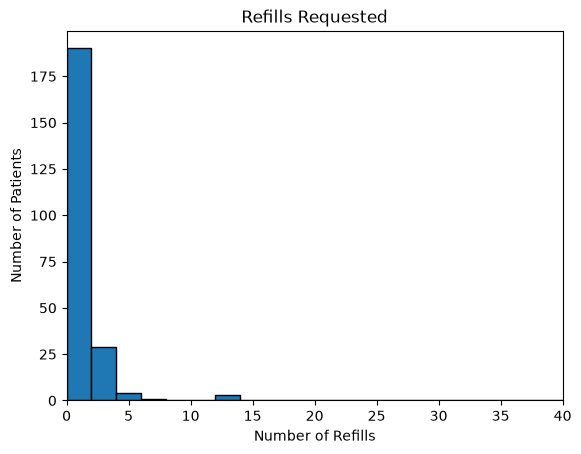

In [98]:
import matplotlib.pyplot as plt
import numpy as np

plt.hist(rx_orders['refills_allowed'].dropna(), bins = np.arange(0,45, 2), edgecolor = "black")
plt.xlim(0,40)
plt.xlabel('Number of Refills')
plt.ylabel("Number of Patients")
plt.title("Refills Requested")

plt.savefig("EDA/hist_refills.png", dpi = 300, bbox_inches = "tight")
plt.show()


In [28]:

print(max(rx_orders['refills_allowed']))

123


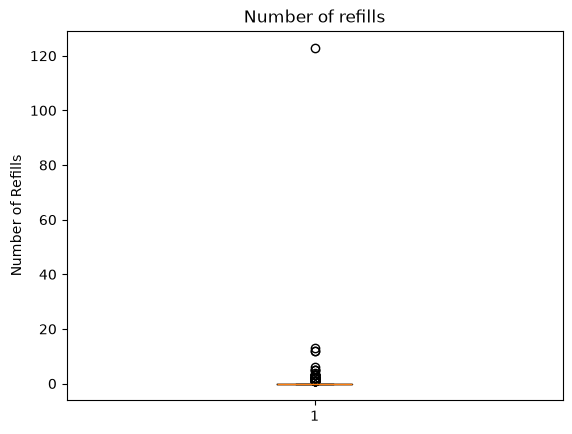

In [29]:
plt.boxplot(rx_orders['refills_allowed'].dropna())
plt.ylabel("Number of Refills")
plt.savefig("EDA/boxplot_refills.png", dpi = 300, bbox_inches = "tight")

plt.title("Number of refills")
plt.show()

In [30]:
rx_orders['quantity'].head()

0    2
1    1
2    3
3    1
4    3
Name: quantity, dtype: int64

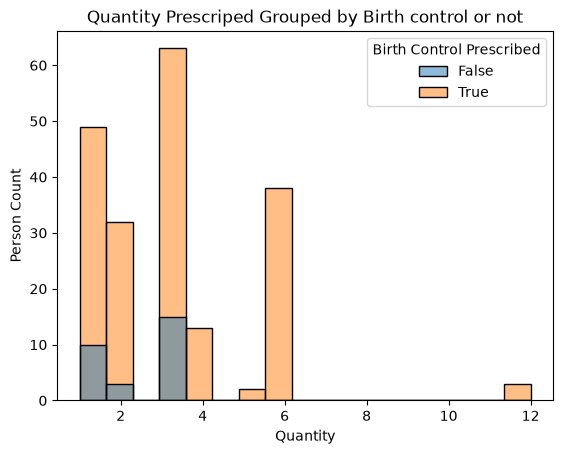

In [31]:
import seaborn as sns
plot=sns.histplot(
    data = rx_orders,
    x="quantity", 
    hue = "bc_prescribed"
)
plot.set(
    xlabel = "Quantity",
    ylabel="Person Count",
    title = "Quantity Prescriped Grouped by Birth control or not"
)

sns.move_legend(
    
    plot, 
    "upper right",
    title = "Birth Control Prescribed"
)
plt.savefig("EDA/quantity_by_bc.png", dpi = 300, bbox_inches = "tight")
plt.show()

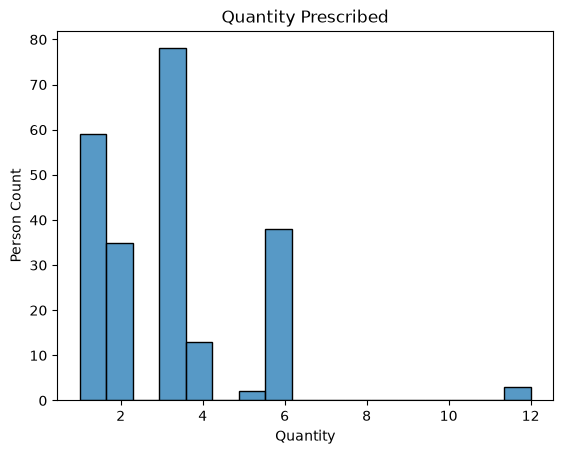

In [101]:
import seaborn as sns
plot=sns.histplot(
    data = rx_orders,
    x="quantity", 
)
plot.set(
    xlabel = "Quantity",
    ylabel="Person Count",
    title = "Quantity Prescribed"
)


plt.savefig("EDA/quantity.png", dpi = 300, bbox_inches = "tight")
plt.show()

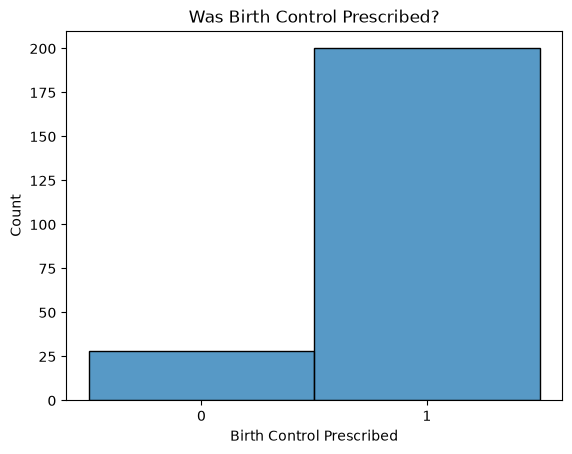

In [32]:

bc=sns.histplot(data = rx_orders, x='bc_prescribed', discrete = True, stat = 'count')
plt.xlabel("Birth Control Prescribed")
plt.title("Was Birth Control Prescribed?")
bc.set_xticks((0,1))
plt.savefig("EDA/bc_prescribed.png", dpi = 300, bbox_inches = "tight")
plt.show()

In [33]:
rx_orders.groupby("bc_prescribed")["quantity"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)


,count,mean,median,std,min,max
bc_prescribed,,,,,,
False,28,2.178571,3.0,0.944911,1,3
True,200,3.140000,3.0,2.042365,1,12


In [34]:
rx_orders['sku'].unique()

<StringArray>
['AD-BC-DAYSEE00', 'AD-BC-FALMIN20', 'AD-BC-ALTAVE00', 'AD-BC-NUVARI00',
 'VC-ASYC-ADCHRG', 'AD-BC-DEPOTP00', 'AD-BC-DROS03LE', 'AD-BC-JUNE20FE',
 'AD-BC-XULANE00', 'AD-BC-EXTERNAL', 'VC-SYNC-15CHRG', 'AD-BC-FREE0000',
 'AD-BC-NEXT3142', 'AD-BC-SLYND000']
Length: 14, dtype: str

In [35]:
rx_orders.groupby("sku")["quantity"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
sku,,,,,,
AD-BC-ALTAVE00,22,3.136364,3.0,0.639602,3,6
AD-BC-DAYSEE00,43,2.372093,2.0,0.756661,2,4
AD-BC-DEPOTP00,30,1.200000,1.0,0.610257,1,3
AD-BC-DROS03LE,13,3.846154,3.0,1.344504,3,6
AD-BC-EXTERNAL,4,2.250000,2.0,1.500000,1,4
AD-BC-FALMIN20,31,1.516129,1.0,1.150970,1,5
AD-BC-FREE0000,1,3.000000,3.0,NaN,3,3
AD-BC-JUNE20FE,38,6.105263,6.0,1.997153,3,12
AD-BC-NEXT3142,4,3.000000,3.0,0.000000,3,3


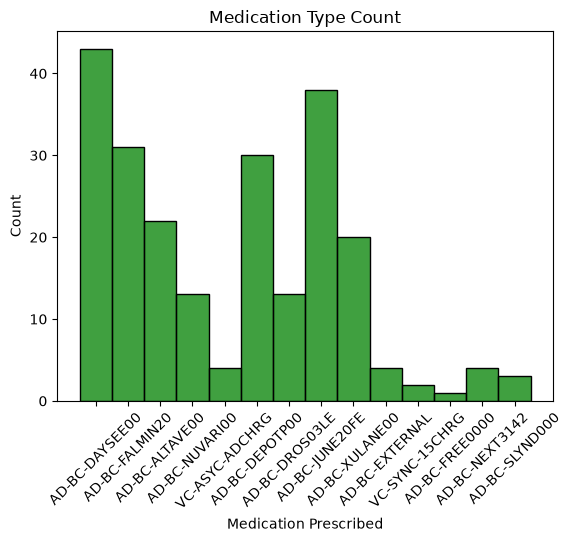

In [36]:
type=sns.histplot(data = rx_orders, x='sku', discrete = True, stat = 'count', color='green')
plt.xlabel("Medication Prescribed")
plt.title("Medication Type Count")
plt.xticks(rotation=45)
#type.set_xticks((0,1))
plt.savefig("EDA/medication_type.png", dpi = 300, bbox_inches = "tight")
plt.show()

In [37]:
#convert to python df
import pandas as pd

with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxWritten;")
    rows = cur.fetchall()
    columns = [col[0] for col in cur.description]

rx_written = pd.DataFrame(rows, columns=columns)

print(rx_written.head())
print(rx_written.shape)  # (rows, columns)

                                     id rx_number       rx_written_date_time  \
0  a9085188-a3b2-4041-8f3c-30f648a65212   XXC72O5 2023-05-11 14:39:10.599092   
1  35824596-5f57-4fdf-b0f2-c93d1408d85d   83QS4Y6 2023-05-11 14:41:16.915695   
2  179c0e3f-2810-4d82-826b-33850c8c5396   XHN4ZFZ 2023-05-11 14:42:02.418655   
3  a2f2a330-8cd5-45ea-b616-47f18154f9a8   FBLCKZH 2023-05-26 18:35:59.986101   
4  c19df9ab-8953-4dae-920a-a5e7fcc13e54   SHOOV4A 2023-05-26 19:24:26.959865   

       rx_creation_date_time rx_expiration_date_time script_status  \
0 2023-05-11 14:39:10.599092     2023-05-24 22:51:58             A   
1 2023-05-11 14:41:16.915695     2023-05-24 22:51:58             A   
2 2023-05-11 14:42:02.418655     2023-05-24 22:51:58             A   
3 2023-05-26 18:35:59.986101     2023-05-27 18:43:15             A   
4 2023-05-26 19:24:26.959865     2023-05-27 19:43:15             A   

            ndc patient_id zip_code  total_fills  total_qty_authorized  \
0  68180-865-71   RWLZIN

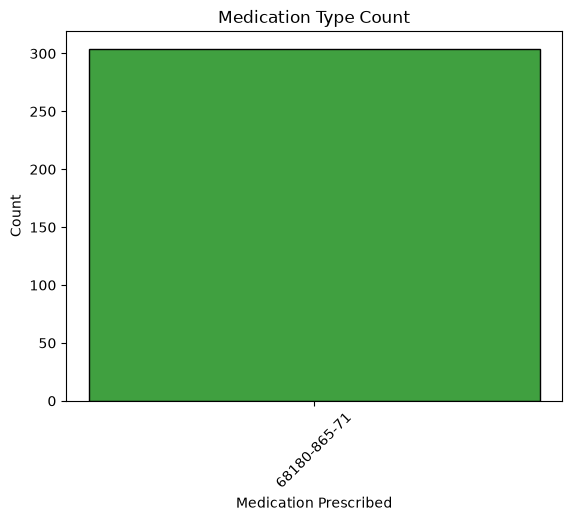

In [38]:
type=sns.histplot(data = rx_written, x='ndc', discrete = True, stat = 'count', color='green')
plt.xlabel("Medication Prescribed")
plt.title("Medication Type Count")
plt.xticks(rotation=45)
#type.set_xticks((0,1))
plt.savefig("EDA/medication_type.png", dpi = 300, bbox_inches = "tight")
plt.show()

In [39]:
rx_written['rx_number'].unique()

<StringArray>
['XXC72O5', '83QS4Y6', 'XHN4ZFZ', 'FBLCKZH', 'SHOOV4A', 'Q2T3G8U', 'A3ZO0ZL',
 'A73ROED', 'OR0VWQ7', 'BIVXZNP',
 ...
 'H9DJCZP', 'WXGV1N2', 'X7XNM4R', 'CIZFDOC', 'KV5MUN0', '55F8ZYK', 'DXNAFEF',
 'GBP95WR', '5C52PU0', 'ORP87A1']
Length: 304, dtype: str

In [40]:
rx_written['rx_written_date_time'].unique()

<DatetimeArray>
['2023-05-11 14:39:10.599092', '2023-05-11 14:41:16.915695',
 '2023-05-11 14:42:02.418655', '2023-05-26 18:35:59.986101',
 '2023-05-26 19:24:26.959865', '2023-05-26 19:25:15.046421',
 '2023-05-09 01:03:44.218225', '2023-06-02 04:23:03.689887',
 '2023-12-14 22:40:08.533193', '2023-10-27 01:26:08.784704',
 ...
 '2024-05-06 22:16:32.087747', '2024-05-06 22:17:23.139404',
 '2024-05-06 22:20:17.860253', '2024-05-06 22:23:18.159869',
 '2024-05-06 22:24:00.780004', '2024-05-06 22:24:36.780118',
 '2024-05-06 22:25:09.918472', '2024-05-06 22:21:45.559838',
 '2024-05-06 21:54:56.689304', '2024-05-06 21:59:18.655339']
Length: 180, dtype: datetime64[us]

In [41]:
rx_written.columns

Index(['id', 'rx_number', 'rx_written_date_time', 'rx_creation_date_time',
       'rx_expiration_date_time', 'script_status', 'ndc', 'patient_id',
       'zip_code', 'total_fills', 'total_qty_authorized', 'rx_source',
       'auto_refill', 'npi_provider_number', 'created_date', 'modified_date',
       'customer_first_name', 'customer_last_name', 'customer_dob',
       'customer_email'],
      dtype='str')

In [42]:
#investigate difference in time between when prescription was written vs created




In [43]:
b

NameError: name 'b' is not defined

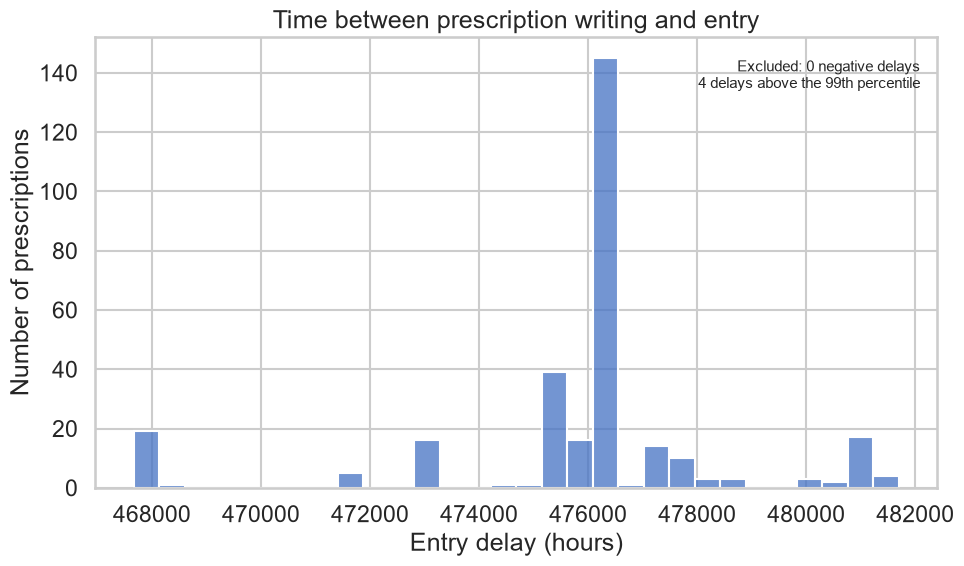

In [ ]:
positive = plot_df.loc[plot_df["delay_hours"] >= 0].copy()
cutoff = positive["delay_hours"].quantile(0.99)

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    data=positive.loc[positive["delay_hours"] <= cutoff],
    x="delay_hours",
    bins=30,
    color="#4472C4",
    ax=ax
)

ax.set(
    title="Time between prescription writing and entry",
    xlabel="Entry delay (hours)",
    ylabel="Number of prescriptions"
)

excluded = (plot_df["delay_hours"] < 0).sum()
long_delays = (positive["delay_hours"] > cutoff).sum()
ax.text(
    0.98, 0.95,
    f"Excluded: {excluded:,} negative delays\n"
    f"{long_delays:,} delays above the 99th percentile",
    transform=ax.transAxes,
    ha="right", va="top", fontsize=11
)

fig.tight_layout()
plt.show()

In [ ]:
#investigate auto refill
rx_written['auto_refill'].unique()

<StringArray>
['N']
Length: 1, dtype: str

In [ ]:
rx_packed['order_receipt_date_time'].unique()

<DatetimeArray>
['2023-05-11 14:39:10.599092', '2023-05-11 14:41:16.915695',
 '2023-05-11 14:42:02.418655', '2023-05-26 18:35:59.986101',
 '2023-05-26 19:24:26.959865', '2023-05-26 19:25:15.046421',
 '2023-05-09 01:03:44.218225', '2023-06-02 04:23:03.689887',
 '2023-12-14 22:40:08.533193', '2023-10-27 01:26:08.784704',
 ...
 '2024-05-06 22:16:32.087747', '2024-05-06 22:17:23.139404',
 '2024-05-06 22:20:17.860253', '2024-05-06 22:23:18.159869',
 '2024-05-06 22:24:00.780004', '2024-05-06 22:24:36.780118',
 '2024-05-06 22:25:09.918472', '2024-05-06 22:21:45.559838',
 '2024-05-06 21:54:56.689304', '2024-05-06 21:59:18.655339']
Length: 181, dtype: datetime64[us]

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid", context="talk")

rx_packed = rx_packed.copy()

rx_packed["received"] = pd.to_datetime(rx_packed["order_receipt_date_time"], errors="coerce")
rx_packed["packed"] = pd.to_datetime(rx_packed["packed_date_time"], errors="coerce")

rx_packed["ship_delay_hours"] = (
    rx_packed["received"] - rx_packed["packed"]
).dt.total_seconds() / 3600

rx_packed["ship_delay_minutes"] = (
    rx_packed["received"] - rx_packed["packed"]
).dt.total_seconds() / 3600/60

# Keep rows with both timestamps
plot_df = rx_packed.dropna(subset=["received", "packed"]).copy()



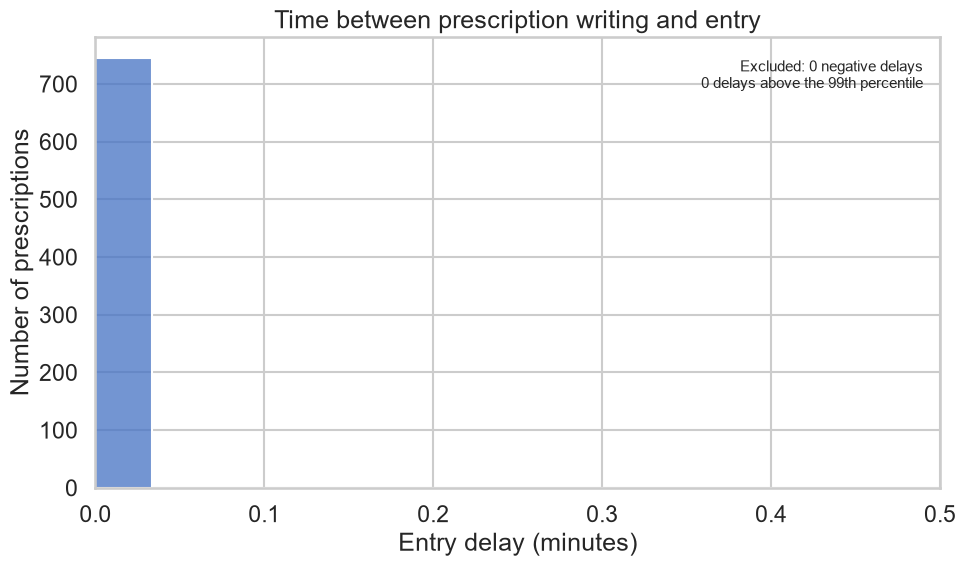

In [ ]:
positive = plot_df.loc[plot_df["ship_delay_minutes"] >= 0].copy()
cutoff = positive["ship_delay_minutes"].quantile(0.99)

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    data=positive.loc[positive["ship_delay_minutes"] <= cutoff],
    x="ship_delay_minutes",
    bins=30,
    color="#4472C4",
    ax=ax
)

ax.set(
    title="Time between prescription writing and entry",
    xlabel="Entry delay (minutes)",
    ylabel="Number of prescriptions"
)

excluded = (plot_df["ship_delay_minutes"] < 0).sum()
long_delays = (positive["ship_delay_minutes"] > cutoff).sum()
ax.text(
    0.98, 0.95,
    f"Excluded: {excluded:,} negative delays\n"
    f"{long_delays:,} delays above the 99th percentile",
    transform=ax.transAxes,
    ha="right", va="top", fontsize=11
)
ax.set_xlim(0, 0.5)
fig.tight_layout()
plt.show()

In [ ]:
rx_packed['ship_delay_hours'].describe()

count    745.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: ship_delay_hours, dtype: float64

In [ ]:
rx_packed.head()

,id,shipment_order,order_receipt_date_time,rx_number,fill_number,qty_req,qty_left,ship_to_state,ship_to_zip_code,packed_date_time,...,tracking_number,created_date,modified_date,ship_to_address1,ship_to_address2,ship_to_city,received,packed,ship_delay_hours,ship_delay_minutes
0,722edc8d-d5d2-4dbb-8706-f20dca0097a3,EJFY1PG,2023-05-11 14:39:10.599092,XXC72O5,X1ME25P,0.0,84.0,WA,98122,2023-05-11 14:39:10.599092,...,9400111206207366050000,2023-05-23 23:05:57.167791,None,None,None,None,2023-05-11 14:39:10.599092,2023-05-11 14:39:10.599092,0.0,0.0
1,4673e3e6-0aa3-4fc0-b23f-9fbf24ff67bf,DDMRDZN,2023-05-11 14:41:16.915695,83QS4Y6,2XCCURQ,0.0,84.0,WA,98122,2023-05-11 14:41:16.915695,...,9400111206207366050000,2023-05-23 23:05:57.190264,None,None,None,None,2023-05-11 14:41:16.915695,2023-05-11 14:41:16.915695,0.0,0.0
2,abd5e5eb-9e95-4837-b1db-7e4ad18eeeb5,UDSFDAO,2023-05-11 14:42:02.418655,XHN4ZFZ,3JGZ0AJ,0.0,84.0,WA,98122,2023-05-11 14:42:02.418655,...,9400111206207366050000,2023-05-23 23:05:57.193918,None,None,None,None,2023-05-11 14:42:02.418655,2023-05-11 14:42:02.418655,0.0,0.0
3,be213e1d-7ef6-49e8-a5dc-1188c84b44fd,QV57OCG,2023-05-26 18:35:59.986101,FBLCKZH,TPE18Q8,0.0,84.0,WA,98112,2023-05-26 18:35:59.986101,...,9400111206207366050000,2023-05-26 18:43:31.531615,None,None,None,None,2023-05-26 18:35:59.986101,2023-05-26 18:35:59.986101,0.0,0.0
4,18f33932-753b-4d53-af2a-4775d4485774,N7NOBHM,2023-05-26 19:24:26.959865,SHOOV4A,64Y3H94,0.0,84.0,WA,98112,2023-05-26 19:24:26.959865,...,9400111206207366050000,2023-05-26 19:43:31.164149,None,None,None,None,2023-05-26 19:24:26.959865,2023-05-26 19:24:26.959865,0.0,0.0


In [ ]:
rx_shipments['state'].unique()

<StringArray>
['MD', 'TN', 'FL', 'WA', 'CO', 'ME', 'MA']
Length: 7, dtype: str

In [ ]:
%pip install "nbformat>=4.2.0"


   ----------- ---------------------------- 2/7 [attrs]
   ---------------------- ----------------- 4/7 [jsonschema-specifications]
   ---------------------------- ----------- 5/7 [jsonschema]
   ---------------------------------- ----- 6/7 [nbformat]
   ---------------------------------- ----- 6/7 [nbformat]
   ---------------------------------------- 7/7 [nbformat]

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [48]:
import plotly.express as px

state_counts = (
    rx_shipments["state"]  # Replace with your state column name
    .str.strip()
    .str.upper()
    .value_counts()
    .rename_axis("state")
    .reset_index(name="shipments")
)

fig = px.choropleth(
    state_counts,
    locations="state",
    locationmode="USA-states",
    color="shipments",
    scope="usa",
    color_continuous_scale="Blues",
    labels={"shipments": "Shipments", "state": "State"},
    title="Shipment Count by State"
)

fig.update_layout(
    title_x=0.5,
    margin=dict(l=0, r=0, t=60, b=0)
)

fig.show()



In [ ]:
%pip install kaleido


   ---------------------------------------- 0/4 [simplejson]
   -------------------- ------------------- 2/4 [choreographer]
   -------------------- ------------------- 2/4 [choreographer]
   ------------------------------ --------- 3/4 [kaleido]
   ---------------------------------------- 4/4 [kaleido]

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [49]:
import plotly.io as pio
pio.get_chrome()

WindowsPath('C:/Users/morga/AppData/Local/plotly/choreographer/deps/chrome-win64/chrome.exe')

In [ ]:
fig.write_image(
    "EDA/shipments_by_state.png",
    width=1400,
    height=900,
    scale=2
)

In [57]:
rx_orders.columns

Index(['id', 'friendly_order_id', 'customer_id', 'stripe_customer_id',
       'status', 'prescriber_id', 'sku', 'quantity', 'signetur',
       'note_to_pharmacy', 'bc_prescribed', 'rx_submitted_to_adyn_pharmacy',
       'refills_allowed', 'customer_cost', 'stripe_price_id',
       'stripe_invoice_item_id', 'stripe_invoice_id', 'date_order_placed',
       'date_order_paid', 'created_date', 'modified_date', 'days_supply',
       'customer_approved', 'adyn_approved', 'customer_disapproved_reason',
       'adyn_disapproved_reason', 'suspended', 'suspended_reason',
       'customer_visibility', 'appointment_id'],
      dtype='str')

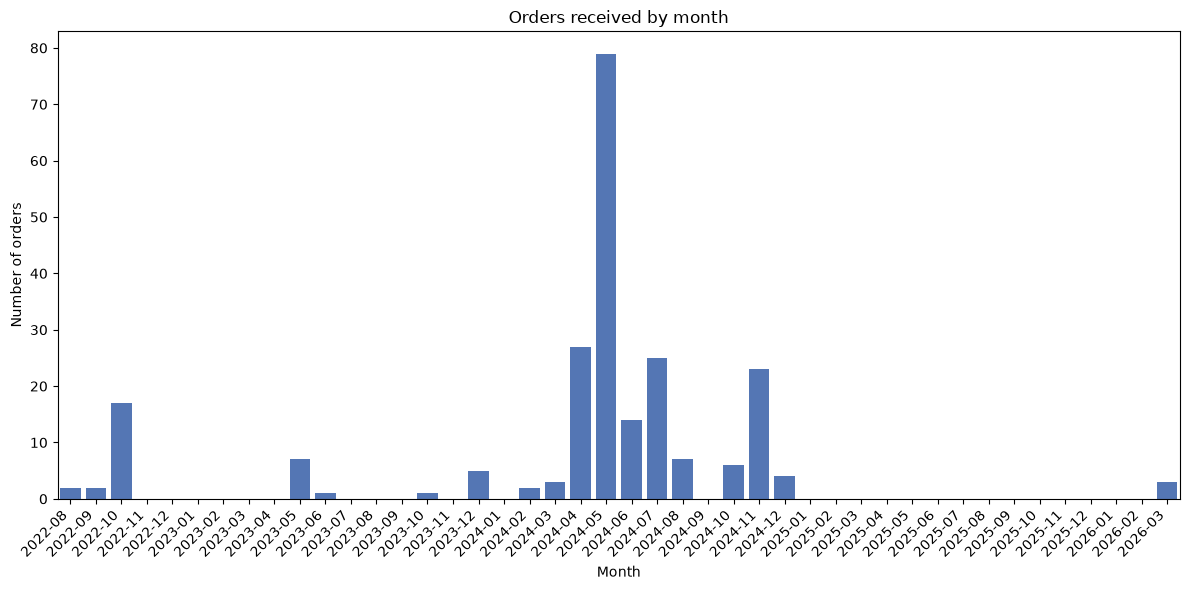

In [ ]:
#investigate busiest months
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rx_orders["date_order_placed"] = pd.to_datetime(
    rx_orders["date_order_placed"],
    errors="coerce"
)

# Keep year and month together, e.g. January 2026
monthly_counts = (
    rx_orders["date_order_placed"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

# Include months with zero orders between the first and last month
monthly_counts = monthly_counts.reindex(
    pd.period_range(
        monthly_counts.index.min(),
        monthly_counts.index.max(),
        freq="M"
    ),
    fill_value=0
)

fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    x=monthly_counts.index.astype(str),
    y=monthly_counts.values,
    color="#4472C4",
    ax=ax
)

ax.set(
    title="Orders received by month",
    xlabel="Month",
    ylabel="Number of orders"
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

fig.tight_layout()

plt.savefig("EDA/hist_mo.png", dpi = 300, bbox_inches = "tight")
plt.show()

In [69]:
rx_written.head()

,id,rx_number,rx_written_date_time,rx_creation_date_time,rx_expiration_date_time,script_status,ndc,patient_id,zip_code,total_fills,total_qty_authorized,rx_source,auto_refill,npi_provider_number,created_date,modified_date,customer_first_name,customer_last_name,customer_dob,customer_email
0,a9085188-a3b2-4041-8f3c-30f648a65212,XXC72O5,2023-05-11 14:39:10.599092,2023-05-11 14:39:10.599092,2023-05-24 22:51:58,A,68180-865-71,RWLZINTD,98122,0.0,0.0,ERX,N,7415,2023-05-23 22:52:10.933714,None,Divya,Bharadwaj,1995-07-28,rx@trigger.adyn.com
1,35824596-5f57-4fdf-b0f2-c93d1408d85d,83QS4Y6,2023-05-11 14:41:16.915695,2023-05-11 14:41:16.915695,2023-05-24 22:51:58,A,68180-865-71,ZORXEGI7,98122,0.0,0.0,ERX,N,7415,2023-05-23 22:52:10.940746,None,Tester,852,1987-07-28,rx@trigger.adyn.com
2,179c0e3f-2810-4d82-826b-33850c8c5396,XHN4ZFZ,2023-05-11 14:42:02.418655,2023-05-11 14:42:02.418655,2023-05-24 22:51:58,A,68180-865-71,J9XDDQDE,98122,0.0,0.0,ERX,N,7415,2023-05-23 22:52:10.948822,None,Tester,850,1988-06-28,rx@trigger.adyn.com
3,a2f2a330-8cd5-45ea-b616-47f18154f9a8,FBLCKZH,2023-05-26 18:35:59.986101,2023-05-26 18:35:59.986101,2023-05-27 18:43:15,A,68180-865-71,FG7M4KKD,98112,0.0,0.0,ERX,N,7415,2023-05-26 18:43:30.975237,None,RxMatch,Tester,2000-04-30,rx@trigger.adyn.com
4,c19df9ab-8953-4dae-920a-a5e7fcc13e54,SHOOV4A,2023-05-26 19:24:26.959865,2023-05-26 19:24:26.959865,2023-05-27 19:43:15,A,68180-865-71,JFGL0PL6,98112,0.0,0.0,ERX,N,7415,2023-05-26 19:43:30.574602,None,RxMatch2,Tester2,2000-12-04,rx@trigger.adyn.com


In [67]:
rx_shipments['delivered_to_customer_date'].value_counts()

delivered_to_customer_date
2022-01-26    74
Name: count, dtype: int64

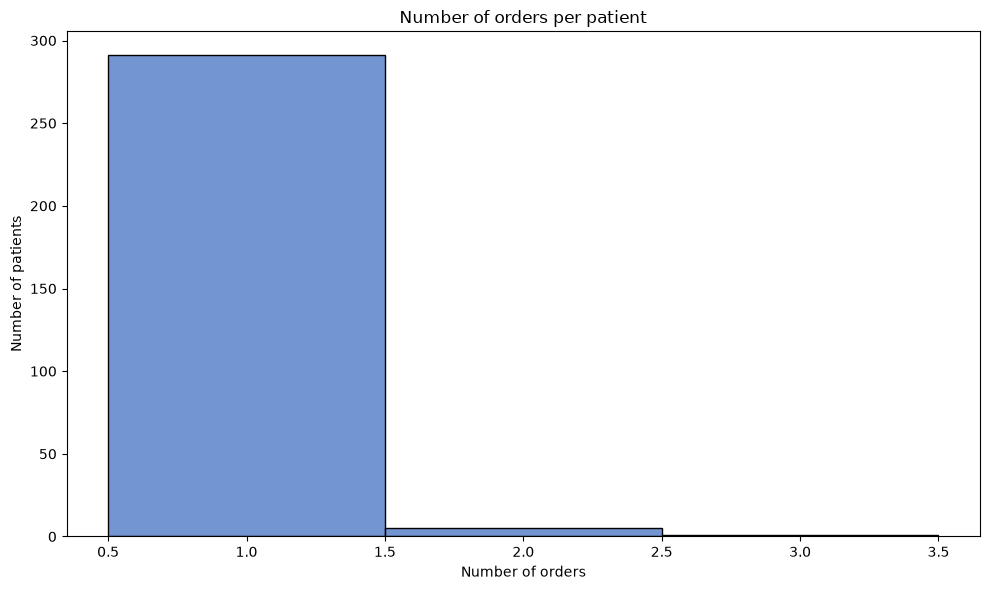

In [71]:
# Replace patient_id with your patient identifier column
orders_per_patient = rx_written.groupby("patient_id").size()

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    x=orders_per_patient,
    discrete=True,
    color="#4472C4",
    ax=ax
)

ax.set(
    title="Number of orders per patient",
    xlabel="Number of orders",
    ylabel="Number of patients"
)

fig.tight_layout()
plt.show()

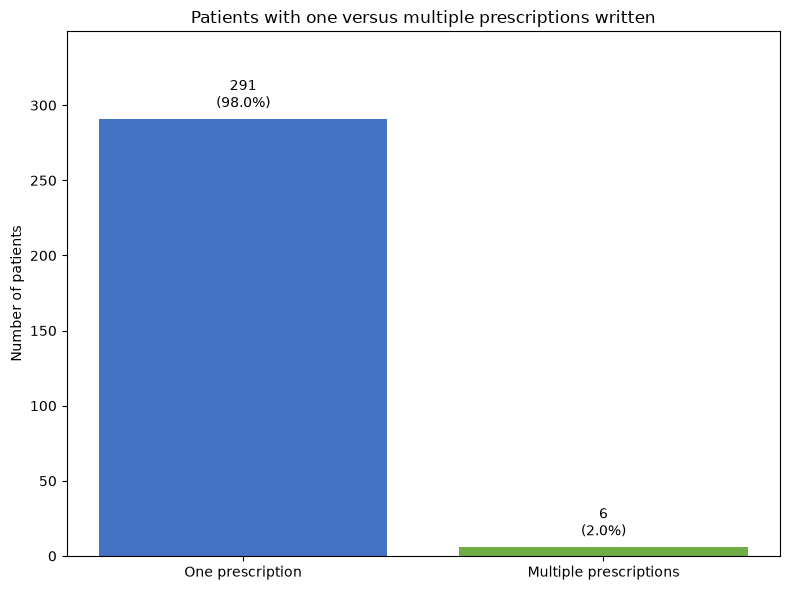

In [75]:
counts = pd.Series({
    "One prescription": (orders_per_patient == 1).sum(),
    "Multiple prescriptions": (orders_per_patient > 1).sum()
})

fig, ax = plt.subplots(figsize=(8, 6))

bars = ax.bar(counts.index, counts.values, color=["#4472C4", "#70AD47"])

ax.bar_label(
    bars,
    labels=[
        f"{count:,}\n({count / counts.sum():.1%})"
        for count in counts
    ],
    padding=5
)

ax.set(
    title="Patients with one versus multiple prescriptions written",
    ylabel="Number of patients"
)
ax.set_ylim(0, counts.max() * 1.2)

fig.tight_layout()
fig.savefig('EDA/multiple_prescript.png')
plt.show()

In [81]:
rx_packed['qty_left'].value_counts()

qty_left
84.0    745
Name: count, dtype: int64

In [89]:
rx_orders.columns

Index(['id', 'friendly_order_id', 'customer_id', 'stripe_customer_id',
       'status', 'prescriber_id', 'sku', 'quantity', 'signetur',
       'note_to_pharmacy', 'bc_prescribed', 'rx_submitted_to_adyn_pharmacy',
       'refills_allowed', 'customer_cost', 'stripe_price_id',
       'stripe_invoice_item_id', 'stripe_invoice_id', 'date_order_placed',
       'date_order_paid', 'created_date', 'modified_date', 'days_supply',
       'customer_approved', 'adyn_approved', 'customer_disapproved_reason',
       'adyn_disapproved_reason', 'suspended', 'suspended_reason',
       'customer_visibility', 'appointment_id'],
      dtype='str')

In [90]:
rx_orders['date_order_paid'].unique()

<DatetimeArray>
['2022-09-05 16:31:30.940148', '2024-05-01 22:27:54.904750',
                        'NaT', '2024-05-01 22:16:59.171881',
 '2024-05-02 00:08:18.523508', '2024-05-03 14:58:19.226323',
 '2024-05-03 18:53:19.409547', '2024-05-08 00:10:14.409465',
 '2024-08-26 15:43:18.923737', '2024-05-01 23:53:19.350060',
 '2024-05-02 00:18:18.911983', '2024-05-03 19:18:18.929643',
 '2024-05-06 19:28:19.029331', '2024-05-07 23:59:39.032867',
 '2024-05-01 23:03:19.091170', '2024-05-07 23:18:52.764748',
 '2024-05-07 23:36:24.870206', '2024-05-07 23:40:17.217927',
 '2024-05-07 23:33:16.582288', '2024-05-07 23:34:44.179186',
 '2024-05-10 16:58:19.470992', '2024-05-07 23:49:41.827008',
 '2024-05-08 00:10:20.379850', '2024-05-08 00:05:43.721861',
 '2024-05-08 16:03:19.412246', '2024-05-09 17:13:19.013730',
 '2024-05-08 17:38:20.692549', '2024-05-08 21:28:19.312561',
 '2024-05-09 16:38:19.518639', '2024-05-09 17:58:18.963768',
 '2024-05-09 18:08:19.045972', '2024-05-09 18:28:19.149038',
 '2024-0

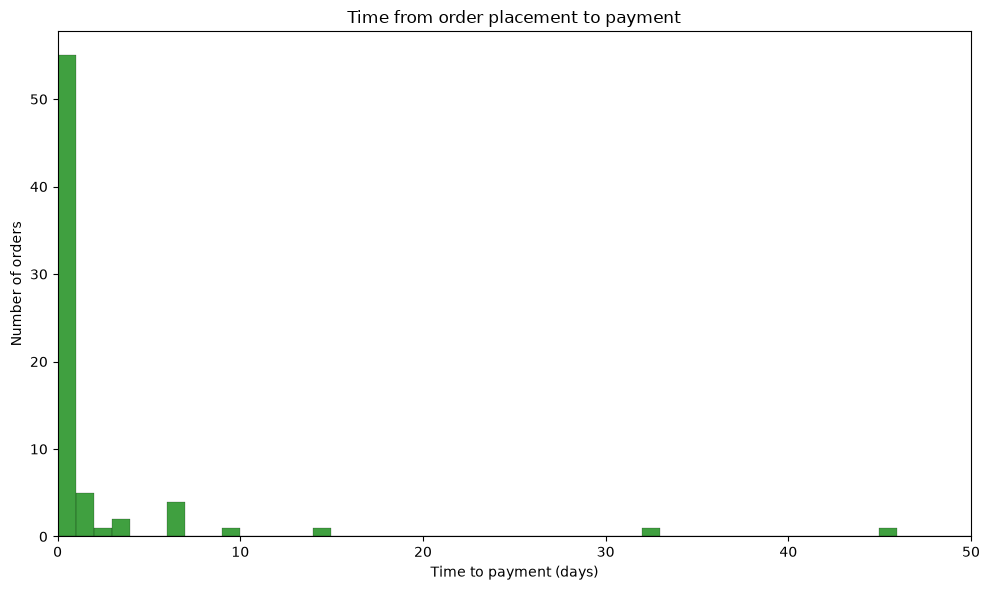

In [97]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rx_orders["date_order_paid"] = pd.to_datetime(
    rx_orders["date_order_paid"], errors="coerce"
)
rx_orders["date_order_placed"] = pd.to_datetime(
    rx_orders["date_order_placed"], errors="coerce"
)

rx_orders["days_to_payment"] = (
    rx_orders["date_order_paid"] - rx_orders["date_order_placed"]
).dt.total_seconds() / 86400

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    data=rx_orders,
    x="days_to_payment",
    binwidth=1,
    color="green",
    ax=ax
)

ax.set(
    title="Time from order placement to payment",
    xlabel="Time to payment (days)",
    ylabel="Number of orders"
)
ax.set_xlim(0,50)
fig.tight_layout()
fig.savefig('EDA/limited_orders_time_difference.png')
plt.show()

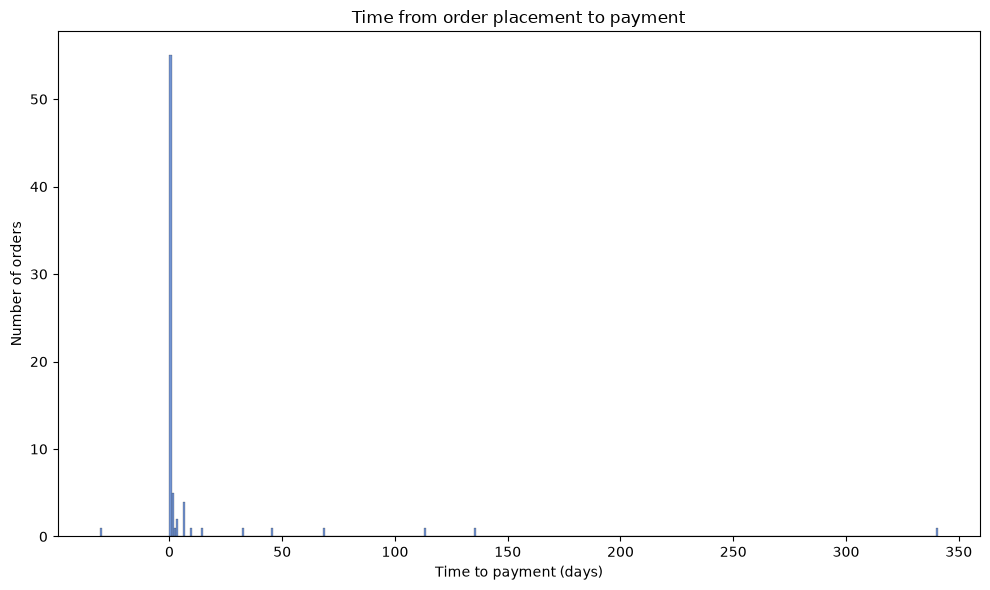

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rx_orders["date_order_paid"] = pd.to_datetime(
    rx_orders["date_order_paid"], errors="coerce"
)
rx_orders["date_order_placed"] = pd.to_datetime(
    rx_orders["date_order_placed"], errors="coerce"
)

rx_orders["days_to_payment"] = (
    rx_orders["date_order_paid"] - rx_orders["date_order_placed"]
).dt.total_seconds() / 86400

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    data=rx_orders,
    x="days_to_payment",
    binwidth=1,
    color="#4472C4",
    ax=ax
)

ax.set(
    title="Time from order placement to payment",
    xlabel="Time to payment (days)",
    ylabel="Number of orders"
)

fig.tight_layout()
fig.savefig('EDA/all_orders_time_difference.png')
plt.show()

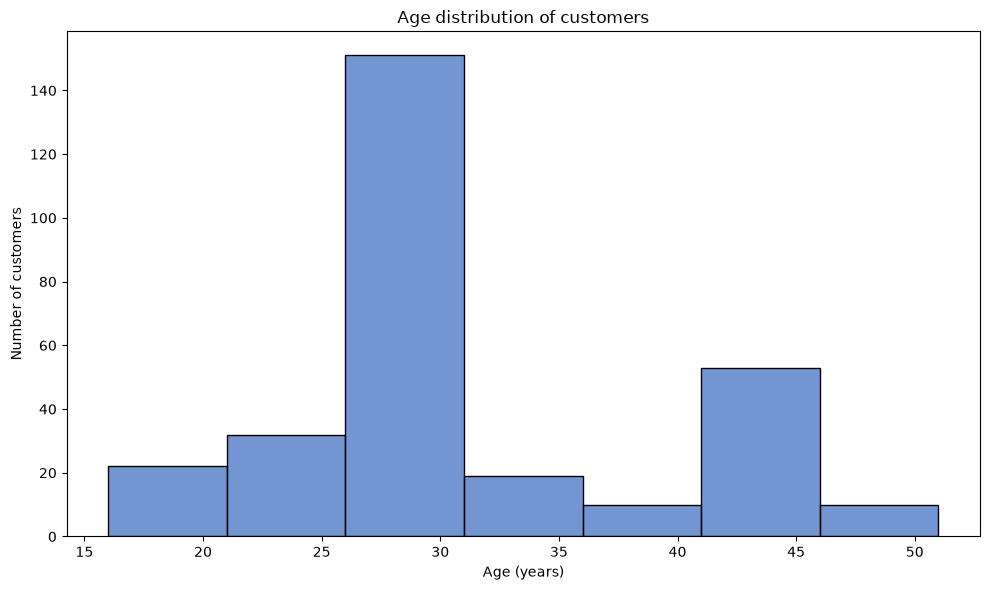

In [85]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# One row per customer so repeat orders don't count them multiple times
customers = rx_written[
    ["patient_id", "customer_dob"]
].drop_duplicates("patient_id").copy()

dob = pd.to_datetime(customers["customer_dob"], errors="coerce")
today = pd.Timestamp.today().normalize()

# Subtract one if their birthday hasn't occurred yet this year
birthday_pending = (
    (dob.dt.month > today.month)
    | ((dob.dt.month == today.month) & (dob.dt.day > today.day))
)

customers["age"] = (
    today.year - dob.dt.year - birthday_pending.astype(int)
)

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    data=customers,
    x="age",
    binwidth=5,
    color="#4472C4",
    ax=ax
)

ax.set(
    title="Age distribution of customers",
    xlabel="Age (years)",
    ylabel="Number of customers"
)

fig.tight_layout()
fig.savefig('EDA/customer_age.png')
plt.show()